# Análise de Dados — Projeto Nossa Entrega

## 1. Contexto

O Projeto Nossa Entrega realiza ações semanais às terças-feiras, com o objetivo de prestar apoio a pessoas em situação de rua.

Para este projeto, foi realizada a **coleta, organização e estruturação de aproximadamente um ano de registros das ações**, reunindo informações sobre a participação dos voluntários e os meios de transporte utilizados.

Para preservar a privacidade dos voluntários, os nomes apresentados nesta versão foram substituídos por nomes fictícios, em atenção à Lei Geral de Proteção de Dados Pessoais (LGPD). Essa adaptação permite apresentar as análises sem divulgar a identidade dos participantes.

A análise tem como foco principal a **participação dos voluntários**, considerando sua evolução ao longo do período, frequência, recorrência, entrada de novos participantes, retorno após a primeira participação e concentração das presenças. De forma complementar, são observados indicadores relacionados à logística de transporte e à participação dos motoristas de carro.

## 2. Objetivo

Transformar os registros coletados em uma base de dados estruturada e analisável, permitindo compreender o comportamento da participação dos voluntários ao longo do período e identificar padrões relevantes de frequência e recorrência.

Como dimensão complementar, a análise também busca apresentar um panorama da disponibilidade de transportes e da participação dos voluntários que atuam como motoristas de carro, contribuindo para o acompanhamento e o planejamento das ações do projeto.


## 3. Exploração inicial dos dados

Nesta etapa, a base coletada e estruturada é importada para o ambiente Python para uma análise inicial de sua estrutura, incluindo dimensões, colunas, tipos de dados e valores ausentes.


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


### 3.1 Carregamento da base

A base utilizada na análise contém os registros coletados das ações do Projeto Nossa Entrega. Os dados originais são mantidos separadamente dos arquivos que serão gerados durante o tratamento e a análise.


In [33]:
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
ARQUIVO = BASE_DIR / "data" / "raw" / "dados_nossa_entrega.xlsx"

excel = pd.ExcelFile(ARQUIVO)
print("Abas disponíveis:", excel.sheet_names)

df = pd.read_excel(ARQUIVO, sheet_name="Participações")

# Adaptação para apresentação: exatamente 48 nomes fictícios brasileiros.
# Aplicada antes de qualquer exibição e sem modificar a planilha de origem.
nomes_ficticios = ['Ana Beatriz Almeida', 'Bruna Carvalho', 'Camila Ferreira', 'Carolina Martins', 'Clara Ribeiro', 'Daniela Costa', 'Eduarda Gomes', 'Fernanda Rocha', 'Gabriela Nunes', 'Helena Barros', 'Isabela Cardoso', 'Juliana Teixeira', 'Larissa Moreira', 'Letícia Azevedo', 'Luana Batista', 'Mariana Oliveira', 'Natália Correia', 'Patrícia Duarte', 'Paula Monteiro', 'Renata Lopes', 'Sabrina Mendes', 'Tatiane Freitas', 'Vanessa Campos', 'Vitória Barbosa', 'André Lima', 'Bruno Pereira', 'Caio Fernandes', 'Carlos Eduardo Souza', 'Daniel Rodrigues', 'Diego Santos', 'Eduardo Vieira', 'Felipe Castro', 'Gabriel Araújo', 'Guilherme Pinto', 'Henrique Moura', 'Igor Reis', 'João Pedro Silva', 'Leonardo Farias', 'Lucas Machado', 'Marcelo Cunha', 'Mateus Ramos', 'Murilo Tavares', 'Pedro Henrique Dias', 'Rafael Martins', 'Ricardo Pires', 'Rodrigo Neves', 'Thiago Albuquerque', 'Vinícius Moraes']
nomes_encontrados = sorted(df["Nome e Sobrenome"].dropna().astype(str).unique())
if len(nomes_encontrados) != len(nomes_ficticios):
    raise ValueError(f"Esperados {len(nomes_ficticios)} voluntários, encontrados {len(nomes_encontrados)}.")
mapa_nomes = dict(zip(nomes_encontrados, nomes_ficticios))
df["Nome e Sobrenome"] = df["Nome e Sobrenome"].replace(mapa_nomes)
del mapa_nomes, nomes_encontrados

df.head()


Abas disponíveis: ['Participações', 'Brief']


,Data,Nome e Sobrenome,Primeira participação?,Tipo de transporte,Quantidade de transportes na ação,Função,Observações
0,2025-09-09,Daniel Rodrigues,Não,Carro,3.0,Motorista,Carro 1
1,2025-09-09,Bruno Pereira,Não,Carro,3.0,Passageiro,Carro 1
2,2025-09-09,Guilherme Pinto,Não,Carro,3.0,Passageiro,Carro 1
3,2025-09-09,Carolina Martins,Não,Carro,3.0,Motorista,Carro 2
4,2025-09-09,Gabriela Nunes,Não,Carro,3.0,Passageiro,Carro 2


### 3.2 Estrutura da base

Após o carregamento, é realizada uma inspeção inicial dos registros para verificar as dimensões da base, as variáveis disponíveis e os tipos de dados.


In [34]:
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

df.info()


Linhas: 328
Colunas: 7
<class 'pandas.DataFrame'>
RangeIndex: 328 entries, 0 to 327
Data columns (total 7 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Data                               328 non-null    datetime64[us]
 1   Nome e Sobrenome                   323 non-null    str           
 2   Primeira participação?             323 non-null    str           
 3   Tipo de transporte                 323 non-null    str           
 4   Quantidade de transportes na ação  323 non-null    float64       
 5   Função                             323 non-null    str           
 6   Observações                        328 non-null    str           
dtypes: datetime64[us](1), float64(1), str(5)
memory usage: 18.1 KB


### 3.3 Qualidade dos dados

Antes do tratamento, são verificadas possíveis inconsistências na base, como valores ausentes, registros duplicados e variações nas categorias utilizadas. Essa etapa permite distinguir problemas de qualidade de ausências previstas pela própria estrutura dos dados.


In [35]:
print("Valores ausentes por coluna:")
display(df.isna().sum())

print(f"Registros duplicados: {df.duplicated().sum()}")


Valores ausentes por coluna:


Data                                 0
Nome e Sobrenome                     5
Primeira participação?               5
Tipo de transporte                   5
Quantidade de transportes na ação    5
Função                               5
Observações                          0
dtype: int64

Registros duplicados: 0


In [36]:
for coluna in [
    "Primeira participação?",
    "Tipo de transporte",
    "Função",
    "Observações"
]:
    print(f"\n{coluna}:")
    print(df[coluna].value_counts(dropna=False))



Primeira participação?:
Primeira participação?
Não    306
Sim     17
NaN      5
Name: count, dtype: int64

Tipo de transporte:
Tipo de transporte
Carro        311
Bicicleta     12
NaN            5
Name: count, dtype: int64

Função:
Função
Passageiro    214
Motorista     109
NaN             5
Name: count, dtype: int64

Observações:
Observações
Carro 1        144
Carro 2        118
Carro 3         49
Bicicleta       12
Sem entrega      5
Name: count, dtype: int64


In [37]:
pd.crosstab(
    df["Tipo de transporte"],
    df["Função"],
    margins=True
)


Função,Motorista,Passageiro,All
Tipo de transporte,,,
Bicicleta,12,0,12
Carro,97,214,311
All,109,214,323


In [38]:
registros_sem_voluntario = df[df["Nome e Sobrenome"].isna()]
registros_sem_voluntario


,Data,Nome e Sobrenome,Primeira participação?,Tipo de transporte,Quantidade de transportes na ação,Função,Observações
117,2025-12-23,NaN,NaN,NaN,NaN,NaN,Sem entrega
118,2025-12-30,NaN,NaN,NaN,NaN,NaN,Sem entrega
119,2026-01-06,NaN,NaN,NaN,NaN,NaN,Sem entrega
120,2026-01-13,NaN,NaN,NaN,NaN,NaN,Sem entrega
121,2026-01-20,NaN,NaN,NaN,NaN,NaN,Sem entrega


In [39]:
nomes = sorted(df["Nome e Sobrenome"].dropna().unique())

print(f"Total de participações: {df['Nome e Sobrenome'].notna().sum()}")
print(f"Voluntários distintos: {df['Nome e Sobrenome'].nunique()}")
nomes


Total de participações: 323
Voluntários distintos: 48


['Ana Beatriz Almeida',
 'Bruna Carvalho',
 'Camila Ferreira',
 'Carolina Martins',
 'Clara Ribeiro',
 'Daniela Costa',
 'Eduarda Gomes',
 'Fernanda Rocha',
 'Gabriela Nunes',
 'Helena Barros',
 'Isabela Cardoso',
 'Juliana Teixeira',
 'Larissa Moreira',
 'Letícia Azevedo',
 'Luana Batista',
 'Mariana Oliveira',
 'Natália Correia',
 'Patrícia Duarte',
 'Paula Monteiro',
 'Renata Lopes',
 'Sabrina Mendes',
 'Tatiane Freitas',
 'Vanessa Campos',
 'Vitória Barbosa',
 'André Lima',
 'Bruno Pereira',
 'Caio Fernandes',
 'Carlos Eduardo Souza',
 'Daniel Rodrigues',
 'Diego Santos',
 'Eduardo Vieira',
 'Felipe Castro',
 'Gabriel Araújo',
 'Guilherme Pinto',
 'Henrique Moura',
 'Igor Reis',
 'João Pedro Silva',
 'Leonardo Farias',
 'Lucas Machado',
 'Felipe Castro Cunha',
 'Mateus Ramos',
 'Murilo Tavares',
 'Pedro Henrique Dias',
 'Rafael Martins',
 'Ricardo Pires',
 'Rodrigo Neves',
 'Thiago Albuquerque',
 'Vinícius Moraes']

In [40]:
nomes_com_espacos = df[
    df["Nome e Sobrenome"].notna() &
    (df["Nome e Sobrenome"] != df["Nome e Sobrenome"].str.strip())
]

nomes_com_espacos


,Data,Nome e Sobrenome,Primeira participação?,Tipo de transporte,Quantidade de transportes na ação,Função,Observações


### Resultado da validação inicial

A base contém 328 registros, sendo 323 participações de 48 voluntários distintos e 5 registros referentes a ações sem entrega.

Não foram identificados registros duplicados nem nomes com espaços excedentes. Os valores ausentes encontrados correspondem exclusivamente às ações registradas como "Sem entrega" e, portanto, são mantidos na base por representarem uma condição válida dos dados.


## 4. Tratamento e preparação dos dados

Após a validação inicial, são realizados os ajustes necessários para garantir a consistência dos dados e preparar a base para as análises. A base original é preservada, e as transformações são aplicadas em uma cópia destinada à análise.


In [41]:
df_analise = df.copy()


### 4.1 Ajuste dos tipos de dados

A variável de quantidade de transportes representa uma contagem e, por isso, é convertida para um tipo inteiro que também permite valores ausentes.


In [42]:
df_analise["Quantidade de transportes na ação"] = (
    df_analise["Quantidade de transportes na ação"].astype("Int64")
)

df_analise["Quantidade de transportes na ação"].dtype


Int64Dtype()

### 4.2 Período analisado

O intervalo temporal da base é verificado a partir da primeira e da última data registradas.


In [43]:
data_inicial = df_analise["Data"].min()
data_final = df_analise["Data"].max()

print(f"Data inicial: {data_inicial:%d/%m/%Y}")
print(f"Data final: {data_final:%d/%m/%Y}")
print(f"Período total: {(data_final - data_inicial).days} dias")


Data inicial: 09/09/2025
Data final: 08/09/2026
Período total: 364 dias


### 4.3 Validação das datas das ações

Como as ações do Projeto Nossa Entrega são realizadas às terças-feiras, as datas presentes na base são verificadas para identificar possíveis registros fora do dia esperado.


In [44]:
df_analise["dia_semana"] = df_analise["Data"].dt.day_name()

df_analise["dia_semana"].value_counts()


dia_semana
Tuesday    328
Name: count, dtype: int64

In [45]:
datas_fora_terca = (
    df_analise.loc[
        df_analise["dia_semana"] != "Tuesday",
        ["Data", "Nome e Sobrenome", "Observações"]
    ]
    .sort_values("Data")
)

datas_fora_terca


,Data,Nome e Sobrenome,Observações


### Resultado da preparação dos dados

Após a revisão e os ajustes realizados, a base de análise mantém 328 registros no período de 09/09/2025 a 08/09/2026. Todos os registros presentes correspondem a terças-feiras, seguindo a periodicidade das ações do projeto.

A base está estruturada e validada para o início da análise exploratória.


## 5. Análise Exploratória de Dados

A análise exploratória busca identificar padrões na participação dos voluntários e na logística de transporte das ações, considerando a evolução ao longo do período, a frequência e recorrência dos participantes e a utilização dos meios de transporte.

### 5.1 Visão geral das ações

Inicialmente, são calculados indicadores gerais para dimensionar a participação dos voluntários e a quantidade de ações registradas no período analisado.

In [46]:
registros_participacao = df_analise[
    df_analise["Nome e Sobrenome"].notna()
]

total_participacoes = len(registros_participacao)
total_voluntarios = registros_participacao["Nome e Sobrenome"].nunique()
total_acoes = registros_participacao["Data"].nunique()

participacoes_por_acao = (
    registros_participacao
    .groupby("Data")
    .size()
)

media_participantes = participacoes_por_acao.mean()
mediana_participantes = participacoes_por_acao.median()
min_participantes = participacoes_por_acao.min()
max_participantes = participacoes_por_acao.max()

print(f"Total de ações com participação: {total_acoes}")
print(f"Total de participações: {total_participacoes}")
print(f"Voluntários distintos: {total_voluntarios}")
print(f"Média de participantes por ação: {media_participantes:.2f}")
print(f"Mediana de participantes por ação: {mediana_participantes:.0f}")
print(f"Menor número de participantes em uma ação: {min_participantes}")
print(f"Maior número de participantes em uma ação: {max_participantes}")

Total de ações com participação: 42
Total de participações: 323
Voluntários distintos: 48
Média de participantes por ação: 7.69
Mediana de participantes por ação: 8
Menor número de participantes em uma ação: 4
Maior número de participantes em uma ação: 10


#### Resultados gerais

No período analisado, foram registradas 42 ações com participação de voluntários, totalizando 323 participações de 48 pessoas distintas.

As ações apresentaram média de 7,69 participantes e mediana de 8 participantes por ação. O número de participantes variou entre 4 e 10 por ação.

Esses indicadores fornecem uma visão geral da dimensão da participação no período e servem como referência para as análises seguintes sobre sua evolução, frequência e recorrência.

### 5.2 Evolução da participação

Para analisar o comportamento da participação ao longo do período, é observada a quantidade de voluntários presentes em cada ação. Essa análise permite identificar oscilações e possíveis mudanças no nível de participação ao longo do tempo.

In [47]:
participacao_por_acao = (
    registros_participacao
    .groupby("Data")
    .size()
    .reset_index(name="Participantes")
    .sort_values("Data")
)

participacao_por_acao

,Data,Participantes
0,2025-09-09,9
1,2025-09-16,7
2,2025-09-23,6
3,2025-09-30,8
4,2025-10-07,8
5,2025-10-14,8
6,2025-10-21,9
7,2025-10-28,9
8,2025-11-04,8
9,2025-11-11,8


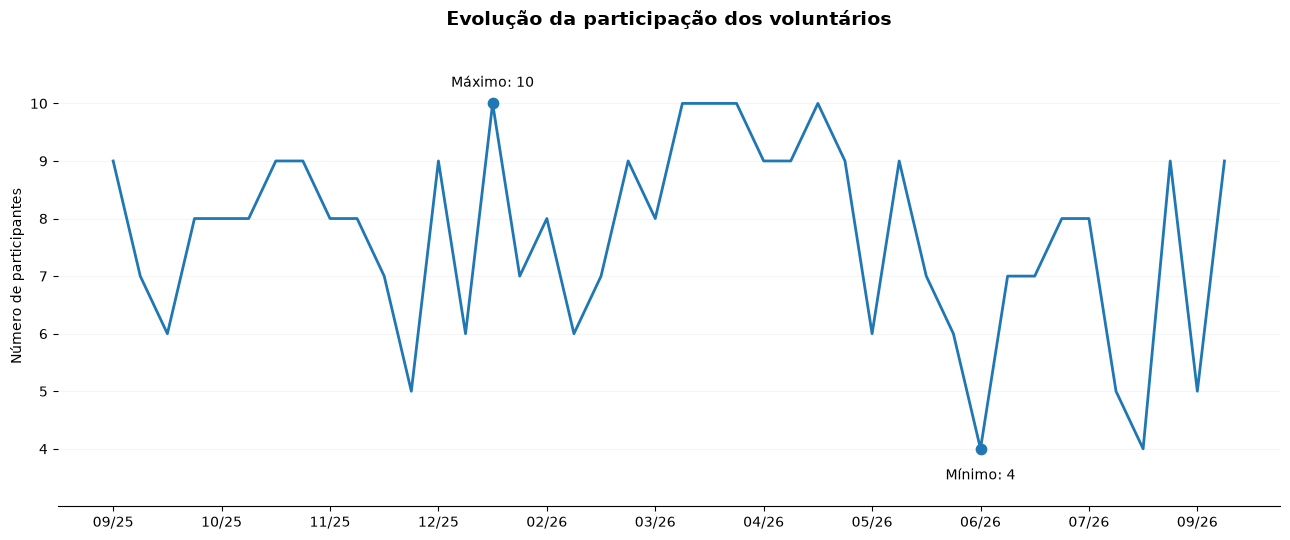

In [60]:
fig, ax = plt.subplots(figsize=(13, 5.5))

x = np.arange(len(participacao_por_acao))
y = participacao_por_acao["Participantes"].to_numpy()

# Linha de participação ao longo das ações
ax.plot(
    x,
    y,
    linewidth=2
)

# Identificação dos valores mínimo e máximo
indice_min = np.argmin(y)
indice_max = np.argmax(y)

ax.scatter(
    [indice_min, indice_max],
    [y[indice_min], y[indice_max]],
    s=55,
    zorder=3
)

# Rótulo do valor mínimo
ax.annotate(
    f"Mínimo: {y[indice_min]}",
    (indice_min, y[indice_min]),
    xytext=(0, -22),
    textcoords="offset points",
    ha="center"
)

# Rótulo do valor máximo
ax.annotate(
    f"Máximo: {y[indice_max]}",
    (indice_max, y[indice_max]),
    xytext=(0, 12),
    textcoords="offset points",
    ha="center"
)

# Datas exibidas no eixo X
posicoes = np.arange(0, len(participacao_por_acao), 4)

ax.set_xticks(posicoes)
ax.set_xticklabels(
    participacao_por_acao.iloc[posicoes]["Data"].dt.strftime("%m/%y")
)

# Escala do eixo Y
ax.set_ylim(3, 11)
ax.set_yticks(range(4, 11))

# Título centralizado
ax.set_title(
    "Evolução da participação dos voluntários",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Número de participantes")
ax.set_xlabel("")

# Limpeza visual
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.12
)

plt.tight_layout()
plt.show()

In [61]:
participacao_por_acao["Periodo"] = pd.cut(
    np.arange(len(participacao_por_acao)),
    bins=[-1, 13, 27, 41],
    labels=[
        "Início do período",
        "Meio do período",
        "Final do período"
    ]
)

resumo_periodos = (
    participacao_por_acao
    .groupby("Periodo", observed=True)["Participantes"]
    .agg(
        Acoes="count",
        Media="mean",
        Mediana="median",
        Minimo="min",
        Maximo="max",
        Desvio_padrao="std"
    )
    .round(2)
)

resumo_periodos

,Acoes,Media,Mediana,Minimo,Maximo,Desvio_padrao
Periodo,,,,,,
Início do período,14,7.64,8.0,5,9,1.28
Meio do período,14,8.71,9.0,6,10,1.33
Final do período,14,6.71,7.0,4,9,1.77


#### Resultados da evolução da participação

Para facilitar a comparação ao longo do período, as 42 ações com participação foram divididas em três blocos cronológicos de 14 ações.

No primeiro bloco, foram registrados em média 7,64 participantes por ação. No bloco intermediário, a média aumentou para 8,71 participantes, com mediana de 9 e máximo de 10.

Nas 14 ações finais, a média caiu para 6,71 participantes por ação, uma redução de aproximadamente 23% em relação ao bloco intermediário. Esse período também apresentou a maior variação na quantidade de participantes, com desvio-padrão de 1,77 e registros entre 4 e 9 participantes.

Os resultados mostram um aumento da participação no bloco intermediário, seguido por redução da média e maior oscilação nas ações finais.


### 5.3 Frequência e recorrência dos voluntários

Nesta etapa, a análise passa a considerar a frequência individual dos voluntários, observando quantas ações cada pessoa participou ao longo do período.

Essa análise permite identificar diferentes níveis de recorrência, desde participações pontuais até voluntários com presença mais frequente nas ações do projeto.

In [62]:
frequencia_voluntarios = (
    registros_participacao
    .groupby("Nome e Sobrenome")
    .agg(
        Participacoes=("Data", "count"),
        Primeira_data=("Data", "min"),
        Ultima_data=("Data", "max")
    )
    .sort_values(
        by=["Participacoes", "Nome e Sobrenome"],
        ascending=[False, True]
    )
)

frequencia_voluntarios

,Participacoes,Primeira_data,Ultima_data
Nome e Sobrenome,,,
Diego Santos,31,2025-09-09,2026-08-11
Bruno Pereira,30,2025-09-09,2026-09-08
Daniel Rodrigues,29,2025-09-09,2026-07-21
Carolina Martins,27,2025-09-09,2026-09-01
Gabriela Nunes,27,2025-09-09,2026-09-01
Guilherme Pinto,26,2025-09-09,2026-09-08
Paula Monteiro,22,2025-09-16,2026-06-16
Eduardo Vieira,13,2025-12-02,2026-08-18
André Lima,12,2025-11-25,2026-09-08


In [63]:
frequencia_voluntarios["Faixa_frequencia"] = pd.cut(
    frequencia_voluntarios["Participacoes"],
    bins=[0, 1, 5, 10, 20, float("inf")],
    labels=[
        "1 participação",
        "2 a 5 participações",
        "6 a 10 participações",
        "11 a 20 participações",
        "Mais de 20 participações"
    ]
)

distribuicao_frequencia = (
    frequencia_voluntarios["Faixa_frequencia"]
    .value_counts(sort=False)
    .rename_axis("Faixa de frequência")
    .reset_index(name="Voluntários")
)

distribuicao_frequencia["Percentual"] = (
    distribuicao_frequencia["Voluntários"]
    / distribuicao_frequencia["Voluntários"].sum()
    * 100
).round(1)

distribuicao_frequencia

,Faixa de frequência,Voluntários,Percentual
0,1 participação,22,45.8
1,2 a 5 participações,12,25.0
2,6 a 10 participações,5,10.4
3,11 a 20 participações,2,4.2
4,Mais de 20 participações,7,14.6


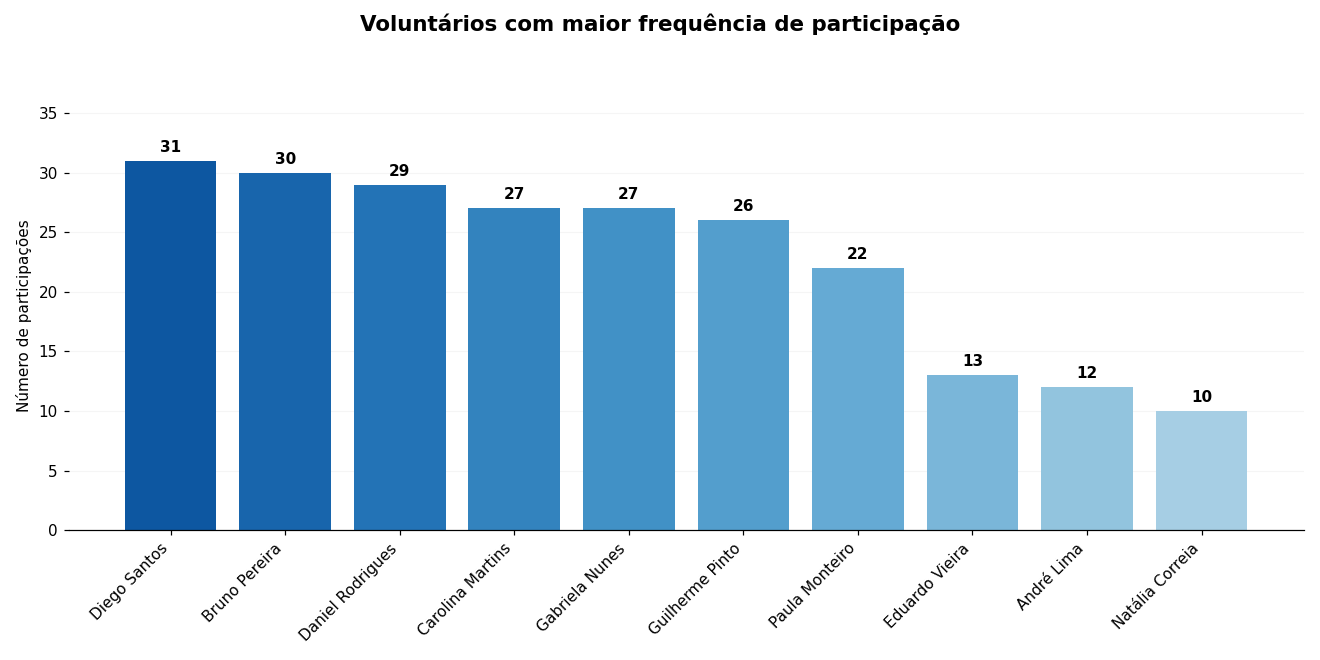

In [73]:
# Seleciona os 10 voluntários com maior número de participações
top_10_voluntarios = (
    frequencia_voluntarios
    .sort_values("Participacoes", ascending=False)
    .head(10)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

nomes = top_10_voluntarios["Nome e Sobrenome"]
participacoes = top_10_voluntarios["Participacoes"]

# Gradiente: mais escuro/vivo para maior frequência
# e progressivamente mais claro até o 10º colocado
cores = plt.cm.Blues(
    np.linspace(0.85, 0.35, len(top_10_voluntarios))
)

# Gráfico
barras = ax.bar(
    nomes,
    participacoes,
    color=cores
)

# Valores acima das barras
for barra, quantidade in zip(barras, participacoes):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.5,
        f"{quantidade}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# Título centralizado
fig.suptitle(
    "Voluntários com maior frequência de participação",
    fontsize=14,
    fontweight="bold",
    x=0.5,
    y=0.98
)

# Eixos
ax.set_ylabel("Número de participações")
ax.set_xlabel("")

# Nomes dos voluntários
plt.xticks(
    rotation=45,
    ha="right"
)

# Escala
ax.set_ylim(0, participacoes.max() + 5)

# Limpeza visual
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.12
)

ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.show()

#### Resultados da frequência e recorrência

A frequência de participação apresenta uma distribuição bastante desigual entre os voluntários. Dos 48 participantes distintos registrados no período, 22 (45,8%) participaram de apenas uma ação, enquanto 12 (25,0%) estiveram presentes entre 2 e 5 ações.

Ao mesmo tempo, observa-se um grupo de voluntários com participação recorrente. Sete pessoas participaram de mais de 20 ações, correspondendo a 14,6% dos voluntários registrados. Entre elas, as maiores frequências foram de Diego Santos (31 participações), Bruno Pereira (30) e Daniel Rodrigues (29).

O resultado evidencia a coexistência de muitas participações pontuais com um grupo menor de voluntários que apresenta alta frequência ao longo do período analisado.

### 5.4 Entrada e retorno de novos voluntários

A análise busca identificar os voluntários cuja primeira participação ocorreu durante o período analisado e verificar se houve retorno nas ações seguintes.

Para essa análise, são considerados novos voluntários apenas os registros identificados como "Sim" na variável "Primeira participação?", diferenciando uma primeira participação efetiva no projeto da primeira ocorrência de um nome na base analisada.

Para tornar a comparação consistente entre participantes que ingressaram em momentos diferentes, o retorno é avaliado considerando as quatro ações seguintes à primeira participação.


In [74]:
novos_voluntarios = (
    registros_participacao[
        registros_participacao["Primeira participação?"] == "Sim"
    ][
        ["Data", "Nome e Sobrenome"]
    ]
    .sort_values("Data")
    .reset_index(drop=True)
)

print(f"Novos voluntários identificados: {len(novos_voluntarios)}")

novos_voluntarios

Novos voluntários identificados: 17


,Data,Nome e Sobrenome
0,2025-10-21,Bruna Carvalho
1,2025-11-11,Larissa Moreira
2,2025-11-18,Murilo Tavares
3,2026-02-03,Camila Ferreira
4,2026-03-03,Clara Ribeiro
5,2026-03-31,Daniela Costa
6,2026-04-07,Vinícius Moraes
7,2026-04-14,Patrícia Duarte
8,2026-05-26,Isabela Cardoso
9,2026-05-26,Tatiane Freitas


In [76]:
# Datas das ações com participação, em ordem cronológica
datas_acoes = (
    registros_participacao["Data"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

def retorno_proximas_4_acoes(nome, data_entrada):
    # Localiza a ação de entrada
    indice_entrada = datas_acoes[datas_acoes == data_entrada].index[0]

    # Seleciona as quatro ações seguintes
    proximas_acoes = datas_acoes.iloc[
        indice_entrada + 1 : indice_entrada + 5
    ]

    # Só é possível avaliar se existem quatro ações posteriores
    if len(proximas_acoes) < 4:
        return pd.Series({
            "Elegível 4 ações": "Não",
            "Retornou em até 4 ações": pd.NA
        })

    retornou = registros_participacao[
        (registros_participacao["Nome e Sobrenome"] == nome)
        & (registros_participacao["Data"].isin(proximas_acoes))
    ].shape[0] > 0

    return pd.Series({
        "Elegível 4 ações": "Sim",
        "Retornou em até 4 ações": "Sim" if retornou else "Não"
    })


retorno_4_acoes = novos_voluntarios.apply(
    lambda linha: retorno_proximas_4_acoes(
        linha["Nome e Sobrenome"],
        linha["Data"]
    ),
    axis=1
)

analise_retorno_4_acoes = pd.concat(
    [novos_voluntarios, retorno_4_acoes],
    axis=1
)

analise_retorno_4_acoes

,Data,Nome e Sobrenome,Elegível 4 ações,Retornou em até 4 ações
0,2025-10-21,Bruna Carvalho,Sim,Não
1,2025-11-11,Larissa Moreira,Sim,Não
2,2025-11-18,Murilo Tavares,Sim,Não
3,2026-02-03,Camila Ferreira,Sim,Sim
4,2026-03-03,Clara Ribeiro,Sim,Não
5,2026-03-31,Daniela Costa,Sim,Não
6,2026-04-07,Vinícius Moraes,Sim,Sim
7,2026-04-14,Patrícia Duarte,Sim,Sim
8,2026-05-26,Isabela Cardoso,Sim,Não
9,2026-05-26,Tatiane Freitas,Sim,Sim


In [77]:
# Considera apenas voluntários com quatro ações posteriores disponíveis
elegiveis_retorno = analise_retorno_4_acoes[
    analise_retorno_4_acoes["Elegível 4 ações"] == "Sim"
].copy()

total_elegiveis = len(elegiveis_retorno)

retornaram_4_acoes = (
    elegiveis_retorno["Retornou em até 4 ações"] == "Sim"
).sum()

nao_retornaram_4_acoes = (
    elegiveis_retorno["Retornou em até 4 ações"] == "Não"
).sum()

taxa_retorno_4_acoes = (
    retornaram_4_acoes / total_elegiveis * 100
)

print(f"Novos voluntários identificados: {len(novos_voluntarios)}")
print(f"Elegíveis para análise de retorno: {total_elegiveis}")
print(f"Retornaram em até 4 ações: {retornaram_4_acoes}")
print(f"Não retornaram em até 4 ações: {nao_retornaram_4_acoes}")
print(f"Taxa de retorno em até 4 ações: {taxa_retorno_4_acoes:.1f}%")

Novos voluntários identificados: 17
Elegíveis para análise de retorno: 11
Retornaram em até 4 ações: 5
Não retornaram em até 4 ações: 6
Taxa de retorno em até 4 ações: 45.5%


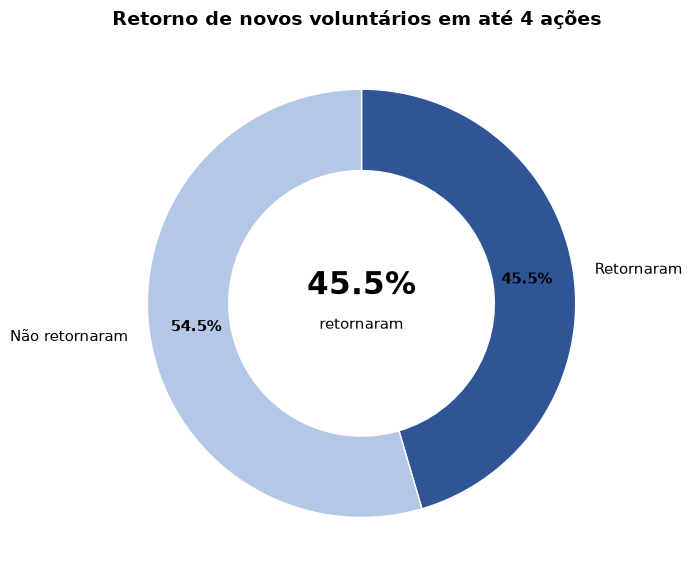

In [78]:
# Dados para o gráfico
valores = [
    retornaram_4_acoes,
    nao_retornaram_4_acoes
]

rotulos = [
    "Retornaram",
    "Não retornaram"
]

cores = [
    "#2F5597",
    "#B4C7E7"
]

# Criação do gráfico
fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(
    valores,
    labels=rotulos,
    colors=cores,
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%",
    pctdistance=0.78,
    wedgeprops={
        "width": 0.38,
        "edgecolor": "white"
    },
    textprops={
        "fontsize": 11
    }
)

# Destaque dos percentuais
for texto in autotexts:
    texto.set_fontweight("bold")
    texto.set_fontsize(11)

# Informação central
ax.text(
    0,
    0.08,
    f"{taxa_retorno_4_acoes:.1f}%",
    ha="center",
    va="center",
    fontsize=22,
    fontweight="bold"
)

ax.text(
    0,
    -0.10,
    "retornaram",
    ha="center",
    va="center",
    fontsize=11
)

# Título
fig.suptitle(
    "Retorno de novos voluntários em até 4 ações",
    fontsize=14,
    fontweight="bold",
    x=0.5,
    y=0.96
)

ax.set_aspect("equal")

plt.tight_layout()
plt.show()

#### Resultados da entrada e retorno de novos voluntários

Ao longo do período analisado, foram identificados 17 novos voluntários. Para tornar a análise de retorno comparável entre participantes que ingressaram em momentos diferentes, foi considerada uma janela de acompanhamento correspondente às quatro ações seguintes à primeira participação.

Dos 17 novos voluntários, 11 possuíam quatro ações posteriores disponíveis na base e puderam ser incluídos nessa análise. Entre eles, 5 retornaram em pelo menos uma das quatro ações seguintes, resultando em uma taxa de retorno de 45,5%. Os outros 6 voluntários (54,5%) não apresentaram nova participação dentro dessa janela.

Os 6 voluntários restantes não foram incluídos no cálculo da taxa, pois ingressaram próximos ao final do período analisado e ainda não possuíam quatro ações posteriores disponíveis para acompanhamento.

O resultado indica que, entre os novos voluntários com janela completa de observação, menos da metade apresentou retorno nas quatro ações seguintes à entrada. Essa métrica representa o retorno inicial observado no período e não deve ser interpretada como uma medida definitiva de permanência dos voluntários no projeto.

### 5.5 Concentração das participações

Após analisar a frequência individual dos voluntários, é importante observar como as participações estão distribuídas entre eles.

Esta etapa busca identificar quanto do total de participações está concentrado entre os voluntários mais frequentes, permitindo avaliar o peso desse grupo na composição das equipes ao longo do período.

In [79]:
# Ordena os voluntários pela quantidade de participações
concentracao_participacoes = (
    frequencia_voluntarios
    .sort_values("Participacoes", ascending=False)
    .reset_index()
)

# Total de participações registradas
total_participacoes = concentracao_participacoes["Participacoes"].sum()

# Participação acumulada
concentracao_participacoes["Participações acumuladas"] = (
    concentracao_participacoes["Participacoes"].cumsum()
)

concentracao_participacoes["Percentual acumulado"] = (
    concentracao_participacoes["Participações acumuladas"]
    / total_participacoes
    * 100
)

# Grupo com mais de 20 participações
grupo_mais_20 = concentracao_participacoes[
    concentracao_participacoes["Participacoes"] > 20
]

quantidade_grupo_mais_20 = len(grupo_mais_20)
participacoes_grupo_mais_20 = grupo_mais_20["Participacoes"].sum()

percentual_voluntarios_mais_20 = (
    quantidade_grupo_mais_20
    / len(concentracao_participacoes)
    * 100
)

percentual_participacoes_mais_20 = (
    participacoes_grupo_mais_20
    / total_participacoes
    * 100
)

print(f"Total de voluntários: {len(concentracao_participacoes)}")
print(f"Total de participações: {total_participacoes}")
print(f"Voluntários com mais de 20 participações: {quantidade_grupo_mais_20}")
print(
    f"Representatividade no total de voluntários: "
    f"{percentual_voluntarios_mais_20:.1f}%"
)
print(
    f"Participações realizadas por esse grupo: "
    f"{participacoes_grupo_mais_20}"
)
print(
    f"Representatividade no total de participações: "
    f"{percentual_participacoes_mais_20:.1f}%"
)

Total de voluntários: 48
Total de participações: 323
Voluntários com mais de 20 participações: 7
Representatividade no total de voluntários: 14.6%
Participações realizadas por esse grupo: 192
Representatividade no total de participações: 59.4%


#### Resultados da concentração das participações

Dos 48 voluntários registrados no período, 7 participaram de mais de 20 ações. Embora representem apenas **14,6% dos voluntários**, esse grupo foi responsável por **192 das 323 participações registradas**, correspondendo a **59,4% do total**.

O resultado evidencia uma concentração das participações em um grupo relativamente pequeno de voluntários, que responde por mais da metade das presenças registradas nas ações.

### 5.6 Logística de transporte

Além da participação dos voluntários, a realização das ações depende da disponibilidade de meios de transporte para o deslocamento das equipes.

Nesta etapa, são analisados os transportes utilizados em cada ação, buscando compreender sua disponibilidade ao longo do período e a composição entre carros e bicicletas.

In [82]:
# Registros das ações com participação
registros_transporte = registros_participacao.copy()

# Quantidade de carros por ação
carros_por_acao = (
    registros_transporte[
        (registros_transporte["Função"] == "Motorista")
        & (registros_transporte["Tipo de transporte"] == "Carro")
    ]
    .groupby("Data")
    .size()
    .rename("Carros")
)

# Quantidade de bicicletas por ação
bicicletas_por_acao = (
    registros_transporte[
        (registros_transporte["Função"] == "Motorista")
        & (registros_transporte["Tipo de transporte"] == "Bicicleta")
    ]
    .groupby("Data")
    .size()
    .rename("Bicicletas")
)

# Total de transportes informado na base
transportes_informados = (
    registros_transporte
    .groupby("Data")["Quantidade de transportes na ação"]
    .first()
    .rename("Transportes informados")
)

# Consolida as informações por ação
logistica_por_acao = (
    pd.concat(
        [
            transportes_informados,
            carros_por_acao,
            bicicletas_por_acao
        ],
        axis=1
    )
    .fillna(0)
    .reset_index()
    .sort_values("Data")
)

# Ajusta as colunas numéricas
logistica_por_acao[
    ["Transportes informados", "Carros", "Bicicletas"]
] = logistica_por_acao[
    ["Transportes informados", "Carros", "Bicicletas"]
].astype(int)

# Total calculado a partir dos tipos de transporte
logistica_por_acao["Transportes calculados"] = (
    logistica_por_acao["Carros"]
    + logistica_por_acao["Bicicletas"]
)

logistica_por_acao

,Data,Transportes informados,Carros,Bicicletas,Transportes calculados
0,2025-09-09,3,3,0,3
1,2025-09-16,2,2,0,2
2,2025-09-23,2,2,0,2
3,2025-09-30,2,2,0,2
4,2025-10-07,3,3,0,3
5,2025-10-14,3,3,0,3
6,2025-10-21,3,3,0,3
7,2025-10-28,3,3,0,3
8,2025-11-04,2,2,0,2
9,2025-11-11,2,2,0,2


In [83]:
# Verifica divergências entre o total informado
# e os transportes identificados nos registros individuais

divergencias_transporte = logistica_por_acao[
    logistica_por_acao["Transportes informados"]
    != logistica_por_acao["Transportes calculados"]
]

print(
    f"Ações com divergência na quantidade de transportes: "
    f"{len(divergencias_transporte)}"
)

divergencias_transporte

Ações com divergência na quantidade de transportes: 1


,Data,Transportes informados,Carros,Bicicletas,Transportes calculados
11,2025-11-25,3,1,1,2


#### Validação dos registros de transporte

A comparação entre a quantidade de transportes informada na base e a quantidade identificada a partir dos registros individuais apresentou correspondência em 41 das 42 ações analisadas.

A única divergência ocorreu em 25/11/2025. Nessa ação, foram informados três transportes, enquanto os registros individuais permitem identificar um carro e uma bicicleta, totalizando dois transportes classificados.

Como a base não permite determinar o tipo do terceiro transporte, essa informação não foi inferida. Para as análises do total de transportes por ação, será utilizada a variável "Quantidade de transportes na ação", que representa diretamente o total registrado para cada ação.

In [85]:
# Indicadores gerais de transporte por ação

total_transportes = logistica_por_acao["Transportes informados"].sum()

media_transportes = (
    logistica_por_acao["Transportes informados"].mean()
)

mediana_transportes = (
    logistica_por_acao["Transportes informados"].median()
)

min_transportes = (
    logistica_por_acao["Transportes informados"].min()
)

max_transportes = (
    logistica_por_acao["Transportes informados"].max()
)

acoes_com_bicicleta = (
    logistica_por_acao["Bicicletas"] > 0
).sum()

percentual_acoes_com_bicicleta = (
    acoes_com_bicicleta
    / len(logistica_por_acao)
    * 100
)

print(f"Total de transportes registrados: {total_transportes}")
print(f"Média de transportes por ação: {media_transportes:.2f}")
print(f"Mediana de transportes por ação: {mediana_transportes:.0f}")
print(f"Menor quantidade de transportes em uma ação: {min_transportes}")
print(f"Maior quantidade de transportes em uma ação: {max_transportes}")
print(f"Ações com presença de bicicleta: {acoes_com_bicicleta}")
print(
    f"Percentual de ações com bicicleta: "
    f"{percentual_acoes_com_bicicleta:.1f}%"
)

Total de transportes registrados: 110
Média de transportes por ação: 2.62
Mediana de transportes por ação: 3
Menor quantidade de transportes em uma ação: 1
Maior quantidade de transportes em uma ação: 4
Ações com presença de bicicleta: 12
Percentual de ações com bicicleta: 28.6%


#### Resultados da logística de transporte

Nas 42 ações analisadas, foram registrados 110 transportes, com média de 2,62 e mediana de 3 transportes por ação. A disponibilidade variou entre 1 e 4 transportes por ação.

As bicicletas estiveram presentes em 12 ações, correspondendo a 28,6% das ações realizadas no período.

Os dados fornecem uma visão geral da estrutura de transporte utilizada pelo projeto, funcionando como informação complementar à análise principal sobre a participação dos voluntários.

### 5.7 Participação dos motoristas de carro

A disponibilidade de carros nas ações depende da participação de voluntários que atuam como motoristas.

Nesta etapa, é analisada a distribuição das participações nessa função, buscando identificar quantos voluntários atuaram como motoristas de carro e como essas participações estão distribuídas entre eles.

In [90]:
# Seleciona apenas participações como motorista de carro
registros_motoristas = registros_participacao[
    (registros_participacao["Função"] == "Motorista")
    & (registros_participacao["Tipo de transporte"] == "Carro")
].copy()

# Frequência de participação de cada motorista
frequencia_motoristas = (
    registros_motoristas
    .groupby("Nome e Sobrenome")
    .agg(
        Participacoes_como_motorista=("Data", "count"),
        Primeira_acao=("Data", "min"),
        Ultima_acao=("Data", "max")
    )
    .sort_values(
        by=["Participacoes_como_motorista", "Nome e Sobrenome"],
        ascending=[False, True]
    )
)

total_participacoes_motorista = len(registros_motoristas)
total_motoristas = registros_motoristas["Nome e Sobrenome"].nunique()

print(
    f"Participações como motorista de carro: "
    f"{total_participacoes_motorista}"
)

print(
    f"Voluntários distintos que atuaram como motorista de carro: "
    f"{total_motoristas}"
)

frequencia_motoristas

Participações como motorista de carro: 97
Voluntários distintos que atuaram como motorista de carro: 13


,Participacoes_como_motorista,Primeira_acao,Ultima_acao
Nome e Sobrenome,,,
Carolina Martins,27,2025-09-09,2026-09-01
Daniel Rodrigues,26,2025-09-09,2026-05-19
Eduardo Vieira,13,2025-12-02,2026-08-18
Mariana Oliveira,9,2025-09-09,2026-07-14
Camila Ferreira,6,2026-02-10,2026-09-01
Natália Correia,5,2025-09-16,2026-02-24
Guilherme Pinto,4,2025-11-25,2026-09-08
Ana Beatriz Almeida,2,2025-10-28,2026-06-30
Helena Barros,1,2026-03-10,2026-03-10


In [91]:
# Concentração das participações entre os motoristas mais frequentes

top_2_motoristas = (
    frequencia_motoristas
    .head(2)["Participacoes_como_motorista"]
    .sum()
)

percentual_top_2_motoristas = (
    top_2_motoristas
    / total_participacoes_motorista
    * 100
)

print(f"Participações dos 2 motoristas mais frequentes: {top_2_motoristas}")
print(
    f"Representatividade no total de participações como motorista: "
    f"{percentual_top_2_motoristas:.1f}%"
)

Participações dos 2 motoristas mais frequentes: 53
Representatividade no total de participações como motorista: 54.6%


#### Resultados da participação dos motoristas de carro

Ao longo do período analisado, 13 voluntários distintos atuaram como motoristas de carro, totalizando 97 participações nessa função.

A distribuição dessas participações apresenta concentração em alguns voluntários. Carolina Martins participou como motorista em 27 ações e Daniel Rodrigues em 26. Juntas, as duas somam 53 participações como motorista, correspondendo a **54,6% do total registrado nessa função**.

O resultado indica que, embora diferentes voluntários tenham atuado como motoristas ao longo do período, mais da metade das participações nessa função esteve concentrada nas duas motoristas mais frequentes.

## 6. Preparação dos dados para visualização

Após a análise exploratória, os dados são organizados em duas tabelas com diferentes níveis de granularidade para utilização no dashboard interativo desenvolvido em **Streamlit e Plotly**:

- **Participações:** uma linha por participação de voluntário em cada ação.
- **Ações:** uma linha por ação realizada, com indicadores consolidados de participação e transporte.

As bases são validadas antes da exportação para garantir a consistência dos dados utilizados no dashboard. O **Streamlit** foi utilizado para desenvolver a aplicação interativa, enquanto o **Plotly** foi utilizado para a construção das visualizações gráficas.

In [92]:
# Base analítica de participações

base_participacoes = (
    registros_participacao[
        [
            "Data",
            "Nome e Sobrenome",
            "Primeira participação?",
            "Tipo de transporte",
            "Função"
        ]
    ]
    .copy()
    .sort_values(
        ["Data", "Nome e Sobrenome"]
    )
    .reset_index(drop=True)
)

# Variáveis temporais úteis para o Power BI
base_participacoes["Ano"] = (
    base_participacoes["Data"].dt.year
)

base_participacoes["Mes"] = (
    base_participacoes["Data"].dt.month
)

base_participacoes["Ano_Mes"] = (
    base_participacoes["Data"].dt.strftime("%Y-%m")
)

print(
    f"Registros na base de participações: "
    f"{len(base_participacoes)}"
)

base_participacoes.head()

Registros na base de participações: 323


,Data,Nome e Sobrenome,Primeira participação?,Tipo de transporte,Função,Ano,Mes,Ano_Mes
0,2025-09-09,Carolina Martins,Não,Carro,Motorista,2025,9,2025-09
1,2025-09-09,Gabriela Nunes,Não,Carro,Passageiro,2025,9,2025-09
2,2025-09-09,Luana Batista,Não,Carro,Passageiro,2025,9,2025-09
3,2025-09-09,Mariana Oliveira,Não,Carro,Motorista,2025,9,2025-09
4,2025-09-09,Bruno Pereira,Não,Carro,Passageiro,2025,9,2025-09


In [93]:
# Base analítica de ações

# Quantidade de participantes por ação
participantes_acao = (
    registros_participacao
    .groupby("Data")
    .size()
    .rename("Participantes")
)

# Quantidade total de transportes registrada por ação
transportes_acao = (
    registros_participacao
    .groupby("Data")["Quantidade de transportes na ação"]
    .first()
    .rename("Transportes")
)

# Quantidade de carros identificados por ação
carros_acao = (
    registros_participacao[
        (registros_participacao["Função"] == "Motorista")
        & (registros_participacao["Tipo de transporte"] == "Carro")
    ]
    .groupby("Data")
    .size()
    .rename("Carros")
)

# Quantidade de bicicletas identificadas por ação
bicicletas_acao = (
    registros_participacao[
        (registros_participacao["Função"] == "Motorista")
        & (registros_participacao["Tipo de transporte"] == "Bicicleta")
    ]
    .groupby("Data")
    .size()
    .rename("Bicicletas")
)

# Consolida os indicadores
base_acoes = (
    pd.concat(
        [
            participantes_acao,
            transportes_acao,
            carros_acao,
            bicicletas_acao
        ],
        axis=1
    )
    .fillna({
        "Carros": 0,
        "Bicicletas": 0
    })
    .reset_index()
    .sort_values("Data")
    .reset_index(drop=True)
)

# Ajusta os tipos numéricos
base_acoes[
    ["Participantes", "Transportes", "Carros", "Bicicletas"]
] = base_acoes[
    ["Participantes", "Transportes", "Carros", "Bicicletas"]
].astype(int)

# Variáveis temporais
base_acoes["Ano"] = base_acoes["Data"].dt.year
base_acoes["Mes"] = base_acoes["Data"].dt.month
base_acoes["Ano_Mes"] = base_acoes["Data"].dt.strftime("%Y-%m")

print(f"Ações na base analítica: {len(base_acoes)}")

base_acoes.head()

Ações na base analítica: 42


,Data,Participantes,Transportes,Carros,Bicicletas,Ano,Mes,Ano_Mes
0,2025-09-09,9,3,3,0,2025,9,2025-09
1,2025-09-16,7,2,2,0,2025,9,2025-09
2,2025-09-23,6,2,2,0,2025,9,2025-09
3,2025-09-30,8,2,2,0,2025,9,2025-09
4,2025-10-07,8,3,3,0,2025,10,2025-10


In [94]:
# Validação final das bases analíticas

print("BASE DE PARTICIPAÇÕES")
print("-" * 40)

print(f"Registros: {len(base_participacoes)}")
print(
    f"Voluntários distintos: "
    f"{base_participacoes['Nome e Sobrenome'].nunique()}"
)
print(
    f"Datas de ações: "
    f"{base_participacoes['Data'].nunique()}"
)
print(
    f"Registros duplicados: "
    f"{base_participacoes.duplicated().sum()}"
)
print(
    f"Datas ausentes: "
    f"{base_participacoes['Data'].isna().sum()}"
)
print(
    f"Nomes ausentes: "
    f"{base_participacoes['Nome e Sobrenome'].isna().sum()}"
)


print("\nBASE DE AÇÕES")
print("-" * 40)

print(f"Ações: {len(base_acoes)}")
print(
    f"Datas duplicadas: "
    f"{base_acoes['Data'].duplicated().sum()}"
)
print(
    f"Datas ausentes: "
    f"{base_acoes['Data'].isna().sum()}"
)
print(
    f"Total de participações: "
    f"{base_acoes['Participantes'].sum()}"
)
print(
    f"Total de transportes: "
    f"{base_acoes['Transportes'].sum()}"
)

BASE DE PARTICIPAÇÕES
----------------------------------------
Registros: 323
Voluntários distintos: 48
Datas de ações: 42
Registros duplicados: 0
Datas ausentes: 0
Nomes ausentes: 0

BASE DE AÇÕES
----------------------------------------
Ações: 42
Datas duplicadas: 0
Datas ausentes: 0
Total de participações: 323
Total de transportes: 110


In [95]:
# Define a pasta de saída
PASTA_PROCESSED = BASE_DIR / "data" / "processed"

# Garante que a pasta exista
PASTA_PROCESSED.mkdir(parents=True, exist_ok=True)

# Define os caminhos dos arquivos
ARQUIVO_PARTICIPACOES = (
    PASTA_PROCESSED / "participacoes.csv"
)

ARQUIVO_ACOES = (
    PASTA_PROCESSED / "acoes.csv"
)

# Exporta as bases processadas
base_participacoes.to_csv(
    ARQUIVO_PARTICIPACOES,
    index=False,
    encoding="utf-8-sig"
)

base_acoes.to_csv(
    ARQUIVO_ACOES,
    index=False,
    encoding="utf-8-sig"
)

print("Bases exportadas com sucesso:")
print(f"- {ARQUIVO_PARTICIPACOES}")
print(f"- {ARQUIVO_ACOES}")

Bases exportadas com sucesso:
- c:\Users\julia\Desktop\projeto-nossa-entrega\data\processed\participacoes.csv
- c:\Users\julia\Desktop\projeto-nossa-entrega\data\processed\acoes.csv


## 7. Conclusão

A análise dos registros do Projeto Nossa Entrega permitiu compreender como a participação dos voluntários se distribuiu ao longo do período analisado e identificar padrões relevantes de frequência, recorrência e retorno.

Foram registradas **323 participações de 48 voluntários distintos em 42 ações**. A participação apresentou comportamentos diferentes ao longo do período: considerando três blocos cronológicos de 14 ações, a média passou de **7,64 participantes por ação** no primeiro bloco para **8,71** no bloco intermediário, seguida por uma redução para **6,71 participantes** nas ações finais, que também apresentaram maior variação no número de participantes.

A frequência individual mostrou uma distribuição desigual. **22 dos 48 voluntários (45,8%) participaram de apenas uma ação**, enquanto **7 voluntários (14,6%) participaram de mais de 20 ações**. Esse grupo de maior frequência concentrou **59,4% das participações registradas**, evidenciando que uma parcela relativamente pequena dos voluntários respondeu por mais da metade das presenças no período.

Entre os **17 novos voluntários** identificados, 11 possuíam uma janela completa de quatro ações posteriores para acompanhamento. Desses, **5 retornaram em pelo menos uma das quatro ações seguintes**, correspondendo a uma taxa de retorno inicial de **45,5%**. Os demais novos participantes não foram incluídos nesse cálculo quando não havia período suficiente de acompanhamento.

Como dimensão complementar, foram registrados **110 transportes**, com média de **2,62 por ação**. A função de motorista de carro também apresentou concentração: **13 voluntários** exerceram essa função, e as duas motoristas mais frequentes responderam juntas por **54,6% das participações como motorista**.

De forma geral, os resultados mostram uma participação sustentada por um grupo de voluntários recorrentes, ao mesmo tempo em que existe entrada de novos participantes e uma parcela expressiva de participações pontuais. O acompanhamento conjunto da frequência, do retorno de novos voluntários e da distribuição das participações pode contribuir para compreender a evolução do quadro de voluntários e apoiar o planejamento das ações do projeto.

As bases processadas a partir desta análise foram utilizadas para o desenvolvimento de um **dashboard interativo em Streamlit e Plotly**, com indicadores, gráficos e análises sobre a participação dos voluntários e a logística das ações. A aplicação organiza os resultados em cinco páginas e facilita o acompanhamento dos indicadores do projeto.
